<div dir="rtl" align="right">

# تشخیص احساس از گفتار فارسی (ShEMO) — نسخه‌ی تقویت‌شده

این نوتبوک، بازنویسی و تقویت‌شده‌ی نوتبوک SER قبلی است. ساختار کلی (CNN روی Mel-spectrogram + LSTM روی MFCC + ensemble) حفظ شده، ولی چند باگ جدی اصلاح و چند بخش مهم اضافه شده است.

## مشکلات نسخه‌ی قبل و اصلاح آن‌ها

| # | مشکل در نسخه‌ی قبل | اصلاح در این نسخه |
|---|---|---|
| 1 | **باگ SpecAugment:** ورودی مدل `[batch, 1, mel, time]` است ولی ماسک روی `shape[0]` و `shape[1]` اعمال می‌شد، یعنی روی محور **batch** و **کانال** نه فرکانس و زمان. نتیجه: در هر batch در هر batch به‌طور میانگین حدود ۷٫۵ نمونه از ۳۲ نمونه کاملاً صفر می‌شد (در شبیه‌سازی کد قبلی روی ۲۰٬۰۰۰ batch: ≈ ۹۴٪ batch‌ها دست‌کم یک نمونه‌ی کاملاً صفر داشتند و ≈ ۲٪ کل batch صفر می‌شد). این با بزرگ‌تر بودن train loss از val loss در لاگ قبلی (۱٫۲۶ در برابر ۰٫۹۳) هم‌خوان است. | استفاده از `FrequencyMasking` و `TimeMasking` با `iid_masks=True` روی محورهای درست؛ ماسک مستقل برای هر نمونه |
| 2 | **LSTM فقط ۱٫۲۵ ثانیه‌ی اول هر فایل را می‌دید:** hop پیش‌فرض MFCC برابر ۲۰۰ نمونه (۱۲٫۵ms) است و طول به ۱۰۰ فریم بریده می‌شد؛ این بازه شامل سکوت ابتدایی هم بود. | حذف سکوت ابتدا/انتها، hop یکسان برای همه‌ی ویژگی‌ها و پنجره‌ی حدود ۵ ثانیه |
| 3 | **Padding با صفر در مقیاس dB:** صفر در مقیاس dB معادل سطح انرژی بالاست نه سکوت (میانگین مجموعه حدود ‎−۱۱ dB بود). | نرمال‌سازی ابتدا، سپس تکرار (tile) فریم‌ها برای فایل‌های کوتاه؛ بدون ساخت «سکوت یا انرژی» مصنوعی |
| 4 | **نشت گوینده (speaker leakage):** تقسیم تصادفی باعث می‌شد گوینده‌ی یکسان هم در train و هم در test باشد؛ دقت خوش‌بینانه می‌شود. | تقسیم مستقل از گوینده با `StratifiedGroupKFold` (گزینه‌ی `split_mode="random"` برای مقایسه با نسخه‌ی قبل باقی است) |
| 5 | انتخاب بهترین مدل با **val accuracy** روی داده‌ی بسیار نامتوازن (Fear حدود ۳۸ نمونه از ۳۰۰۰). | انتخاب با **macro-F1**؛ گزارش UAR، F1 هر کلاس و بازه‌ی اطمینان bootstrap |
| 6 | فایل‌های wav در **هر epoch** دوباره خوانده و ویژگی‌ها محاسبه می‌شد؛ `print` دیباگ داخل `__getitem__`. | ویژگی‌ها یک‌بار محاسبه و در حافظه نگه‌داری می‌شوند؛ آموزش بسیار سریع‌تر |
| 7 | LSTM: فقط ۱۳ ضریب MFCC خام، نرمال‌سازی اسکالر، ۲۰ epoch با `lr=1e-4`، بدون ذخیره‌ی بهترین مدل. | MFCC-40 + Δ + ΔΔ، نرمال‌سازی **به ازای هر ضریب**، BiLSTM دولایه + attentive pooling، OneCycle، early stopping |
| 8 | Ensemble با وزن ثابت ۵۰/۵۰ و LSTM ضعیف‌تر (val ≈ ۰٫۶۲ در برابر ≈ ۰٫۷۷ برای CNN) باعث پایین آمدن نتیجه می‌شد. | وزن ensemble روی **validation** تنظیم می‌شود |
| 9 | ریزباگ‌ها: `test_labels` بازنویسی می‌شد، پوشه‌ی `/content/visual` ساخته نمی‌شد، برچسب confusion matrix عدد بود نه نام احساس، فرض mono بودن فایل. | همه اصلاح شد |

## چه چیزی اضافه شد؟

- **شاخه‌ی سوم: امبدینگ مدل پیش‌آموزش‌دیده‌ی SSL** (`XLS-R 300M`، چندزبانه) با وزن‌دهی یادگیری‌پذیر روی لایه‌ها. معمولاً قوی‌ترین شاخه در SER با داده‌ی کم است.
- Mixup، label smoothing، وزن کلاس نرم‌شده (توان ۰٫۵ به‌جای ۱٫۰)، clip گرادیان، AMP.
- ارزیابی کامل: Acc / UAR / macro-F1 / گزارش هر کلاس / confusion matrix نرمال‌شده / بازه‌ی اطمینان.
- ذخیره‌ی مدل‌ها و تابع `predict_emotion(path)` برای استنتاج روی یک فایل.
- اعتبارسنجی متقاطع اختیاری (`RUN_CV`).

> **نکته‌ی مقایسه:** چون این نسخه به‌صورت پیش‌فرض تقسیم **مستقل از گوینده** دارد، اعداد آن مستقیماً با اعداد نسخه‌ی قبل (تقسیم تصادفی) قابل مقایسه نیست و معمولاً پایین‌تر است، ولی تخمین واقعی‌تری از عملکرد روی گوینده‌ی جدید می‌دهد. برای مقایسه‌ی منصفانه، `split_mode="random"` را بگذارید.

</div>

<div dir="rtl" align="right">

## ۱. راه‌اندازی و پیکربندی

همه‌ی هایپرپارامترها در یک `Config` جمع شده‌اند تا آزمایش‌ها قابل تکرار و قابل مقایسه باشند. اگر زمان کم دارید، `use_ssl=False` را بگذارید (شاخه‌ی XLS-R حذف می‌شود).

</div>

In [4]:
%pip install -q kagglehub soundfile transformers

In [5]:
import os, re, gc, json, math, time, random, hashlib, itertools, warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")
warnings.filterwarnings("ignore", message=".*least populated class.*")


@dataclass
class Config:
    # ---- paths
    data_dir: str = "/content/shemo"
    work_dir: str = "/content/ser_outputs"
    kaggle_slug: str = "mansourehk/shemo-persian-speech-emotion-detection-database"
    # ---- audio / features
    sr: int = 16000
    max_sec: float = 10.0          # hard cap on stored utterance length
    trim_top_db: float = 35.0      # leading/trailing silence trimming threshold
    n_fft: int = 1024
    hop: int = 256                 # 16 ms at 16 kHz
    n_mels: int = 96
    n_mfcc: int = 40
    crop_sec: float = 5.0          # model input length (random crop in training)
    # ---- split
    split_mode: str = "speaker"    # "speaker" (speaker-independent) | "random" (as in the old notebook)
    n_folds: int = 10
    test_fold: int = 0
    seed: int = 42
    # ---- training
    batch_size: int = 64
    epochs_cnn: int = 60
    epochs_rnn: int = 60
    epochs_ssl: int = 80
    lr_cnn: float = 2e-3
    lr_rnn: float = 2e-3
    lr_ssl: float = 1e-3
    weight_decay: float = 1e-2
    patience: int = 15
    label_smoothing: float = 0.05
    class_weight_power: float = 0.5   # 0 = no weighting, 1 = fully balanced
    mixup_alpha: float = 0.2
    cnn_widths: tuple = (32, 64, 128, 256)
    rnn_hidden: int = 128
    # ---- pretrained SSL branch
    use_ssl: bool = True
    ssl_name: str = "facebook/wav2vec2-xls-r-300m"
    ssl_max_sec: float = 10.0

    @property
    def crop_frames(self):
        return int(self.crop_sec * self.sr / self.hop)


CFG = Config()


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


seed_everything(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"                  # mixed precision only on GPU
torch.backends.cudnn.benchmark = True
WORK = Path(CFG.work_dir); WORK.mkdir(parents=True, exist_ok=True)

print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print("crop frames:", CFG.crop_frames)

torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | device: cuda (Tesla T4)
crop frames: 312


<div dir="rtl" align="right">

## ۲. داده: دانلود، متادیتا و بررسی توزیع

نام فایل‌های ShEMO به شکل `F01A01.wav` است: حرف اول جنسیت (`F`/`M`)، دو رقم بعدی کد گوینده، حرف چهارم احساس (`A` خشم، `S` غم، `F` ترس، `H` شادی، `W` تعجب، `N` خنثی) و دو رقم آخر کد جمله.
علاوه بر برچسب احساس، **شناسه‌ی گوینده** (`F01`) را هم استخراج می‌کنیم؛ برای تقسیم‌بندی مستقل از گوینده لازم است.

</div>

In [6]:

# ============================================================
# AUTOMATIC ShEMO DATASET DISCOVERY AND COPY TO /content/
# ============================================================

import os
import shutil
from pathlib import Path

# Destination directory
DEST_DIR = Path("/content/ShEMO")

# Possible dataset locations in Google Colab
SEARCH_DIRS = [
    Path("/content"),
    Path("/root/.cache/kagglehub/datasets"),
    Path("/root/.cache"),
    Path("/kaggle/input"),
]

print("=" * 65)
print("ShEMO DATASET AUTO-DISCOVERY")
print("=" * 65)

# ------------------------------------------------------------
# 1. Find all WAV files in available locations
# ------------------------------------------------------------

wav_files = []

for search_dir in SEARCH_DIRS:

    if not search_dir.exists():
        continue

    print(f"Searching: {search_dir}")

    for file in search_dir.rglob("*"):

        # Avoid searching inside the destination directory
        try:
            if DEST_DIR in file.parents or file == DEST_DIR:
                continue
        except Exception:
            pass

        if file.is_file() and file.suffix.lower() == ".wav":
            wav_files.append(file)

# Remove duplicates
wav_files = list(dict.fromkeys(wav_files))

print(f"\nTotal WAV files discovered: {len(wav_files)}")

if len(wav_files) == 0:
    raise FileNotFoundError(
        "No WAV files found. Check whether ShEMO is downloaded "
        "or mounted correctly."
    )

# ------------------------------------------------------------
# 2. Display discovered dataset locations
# ------------------------------------------------------------

print("\nSample discovered files:")

for f in wav_files[:10]:
    print(" ", f)

# ------------------------------------------------------------
# 3. Copy audio files into /content/ShEMO
# ------------------------------------------------------------

DEST_DIR.mkdir(parents=True, exist_ok=True)

# Find a common source directory to preserve folder structure
source_root = Path(
    os.path.commonpath([str(f.parent) for f in wav_files])
)

copied = 0
skipped = 0

for src in wav_files:

    try:
        relative_path = src.relative_to(source_root)
    except ValueError:
        relative_path = Path(src.name)

    dst = DEST_DIR / relative_path

    dst.parent.mkdir(parents=True, exist_ok=True)

    if dst.exists() and dst.stat().st_size == src.stat().st_size:
        skipped += 1
        continue

    shutil.copy2(src, dst)
    copied += 1

print("\n" + "=" * 65)
print("COPY COMPLETED")
print("=" * 65)

# ------------------------------------------------------------
# 4. Verify copied dataset
# ------------------------------------------------------------

final_wav_files = list(DEST_DIR.rglob("*.wav"))

# Also handle uppercase extensions
final_wav_files += [
    f for f in DEST_DIR.rglob("*.WAV")
    if f not in final_wav_files
]

print(f"Copied files: {copied}")
print(f"Already existing files: {skipped}")
print(f"Total WAV files in destination: {len(final_wav_files)}")

if len(final_wav_files) == 0:
    raise RuntimeError("Dataset copy verification failed!")

# ------------------------------------------------------------
# 5. Update notebook configuration
# ------------------------------------------------------------

CFG.data_dir = str(DEST_DIR)

print(f"\nDataset directory set to: {CFG.data_dir}")
print("Dataset is ready for preprocessing!")

print("=" * 65)


ShEMO DATASET AUTO-DISCOVERY
Searching: /content
Searching: /root/.cache
Searching: /kaggle/input

Total WAV files discovered: 3000

Sample discovered files:
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F13A20.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F23A06.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F24N09.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F24S05.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F21W01.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F24S01.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F24A43.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F05S01.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F09N03.wav
  /kaggle/input/shemo-persian-speech-emotion-detection-database/female/F03S15.wav

COPY COMPLETED
Copied

wav files found: 3000


reading headers:   0%|          | 0/3000 [00:00<?, ?it/s]


utterances: 3000 | speakers: 87 | female/male utterances: 1263/1737
sample rates: {44100: 2869, 22050: 131}
count    3000.00
mean        4.11
std         3.41
min         0.36
25%         1.96
50%         3.08
75%         5.10
max        33.33


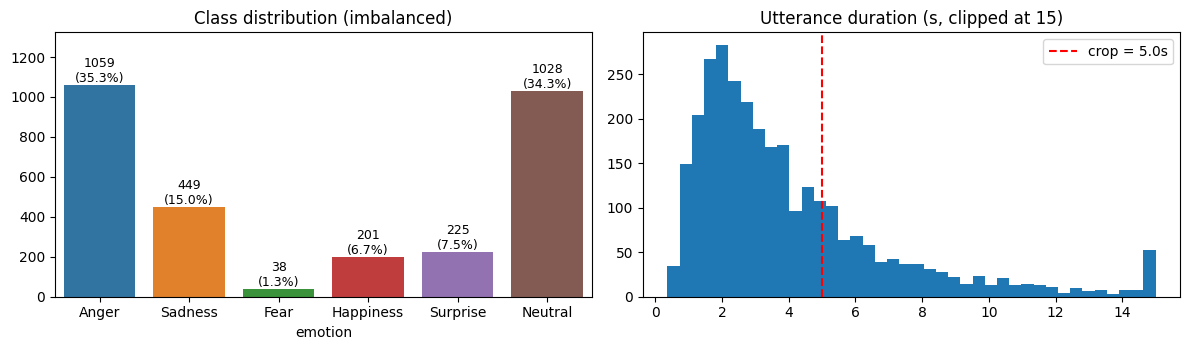

fraction of utterances longer than the crop: 25.9%


In [7]:
DATA_DIR = Path(CFG.data_dir); DATA_DIR.mkdir(parents=True, exist_ok=True)
if not any(DATA_DIR.rglob("*.wav")):
    import kagglehub
    kagglehub.dataset_download(CFG.kaggle_slug, output_dir=str(DATA_DIR))
wav_files = sorted(DATA_DIR.rglob("*.wav"))
print("wav files found:", len(wav_files))

EMOTIONS = {"A": "Anger", "S": "Sadness", "F": "Fear", "H": "Happiness", "W": "Surprise", "N": "Neutral"}
CODES = list(EMOTIONS)                              # label id = position (same mapping as the old notebook)
CLASS_NAMES = [EMOTIONS[c] for c in CODES]
N_CLASSES = len(CLASS_NAMES)

pattern = re.compile(r"^([FM])(\d{2})([AHNSWF])(\d{2})\.wav$", re.IGNORECASE)
rows, skipped = [], []
for p in wav_files:
    m = pattern.match(p.name)
    if m is None:
        skipped.append(p.name); continue
    g, spk, emo, sent = m.groups()
    g, emo = g.upper(), emo.upper()
    rows.append(dict(path=str(p), file=p.name, gender=g, speaker=g + spk,
                     emotion=EMOTIONS[emo], label=CODES.index(emo), sentence=sent))
df = pd.DataFrame(rows)
if skipped:
    print(f"skipped {len(skipped)} files with unexpected names, e.g. {skipped[:3]}")
assert len(df) > 0, "No ShEMO-style file names were found; check CFG.data_dir"

info = [sf.info(p) for p in tqdm(df.path, desc="reading headers")]
df["duration"] = [i.duration for i in info]
df["orig_sr"] = [i.samplerate for i in info]

print(f"\nutterances: {len(df)} | speakers: {df.speaker.nunique()} | "
      f"female/male utterances: {(df.gender == 'F').sum()}/{(df.gender == 'M').sum()}")
print("sample rates:", df.orig_sr.value_counts().to_dict())
print(df.duration.describe().round(2).to_string())

counts = df.emotion.value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], hue=counts.index, legend=False)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Class distribution (imbalanced)"); ax[0].set_ylim(0, counts.max() * 1.25)
ax[1].hist(df.duration.clip(upper=15), bins=40); ax[1].axvline(CFG.crop_sec, color="r", ls="--", label=f"crop = {CFG.crop_sec}s")
ax[1].set_title("Utterance duration (s, clipped at 15)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"fraction of utterances longer than the crop: {(df.duration > CFG.crop_sec).mean():.1%}")

<div dir="rtl" align="right">

## ۳. پیش‌پردازش و استخراج ویژگی (یک‌بار، با cache)

مراحل برای هر فایل:

1. تبدیل به mono و resample به ۱۶ kHz (با `soundfile`، بدون وابستگی به backend ‏torchaudio)؛
2. **حذف سکوت ابتدا و انتها** بر اساس انرژی نسبی (۳۵ dB زیر قوی‌ترین فریم)؛
3. نرمال‌سازی قله (peak) برای کم‌کردن اثر بهره‌ی ضبط؛
4. محاسبه‌ی **log-Mel** (۹۶ باند) برای CNN و **MFCC-40 + Δ + ΔΔ** (۱۲۰ بعد) برای LSTM، هر دو با hop برابر ۱۶ms تا طول دنباله یکسان باشد.

ویژگی‌ها فقط یک‌بار محاسبه می‌شوند؛ در هر epoch فقط برش (crop) و نرمال‌سازی انجام می‌شود.

</div>

In [8]:
_RESAMPLERS = {}

def _resample(wav, orig_sr):
    if orig_sr == CFG.sr:
        return wav
    if orig_sr not in _RESAMPLERS:
        _RESAMPLERS[orig_sr] = torchaudio.transforms.Resample(orig_sr, CFG.sr)
    return _RESAMPLERS[orig_sr](wav)


def trim_silence(wav, top_db, min_len=8000):
    """Drop leading/trailing frames whose energy is more than `top_db` below the loudest frame."""
    frame, hop = int(0.025 * CFG.sr), int(0.010 * CFG.sr)
    if wav.numel() < frame + hop:
        return wav
    frames = wav.unfold(0, frame, hop)
    rms_db = 10 * torch.log10(frames.pow(2).mean(1) + 1e-10)
    keep = torch.nonzero(rms_db > rms_db.max() - top_db).flatten()
    if keep.numel() == 0:
        return wav
    start, end = int(keep[0]) * hop, min(wav.numel(), int(keep[-1]) * hop + frame)
    return wav[start:end] if end - start >= min_len else wav


def load_waveform(path):
    """File -> mono 16 kHz float32 tensor, silence-trimmed, peak-normalised, capped at max_sec."""
    x, sr = sf.read(path, dtype="float32", always_2d=True)       # [N, channels]
    wav = _resample(torch.from_numpy(x.mean(axis=1)), sr)
    wav = trim_silence(wav, CFG.trim_top_db)
    wav = wav / (wav.abs().max() + 1e-8)
    return wav[: int(CFG.max_sec * CFG.sr)]


mel_tf = torchaudio.transforms.MelSpectrogram(sample_rate=CFG.sr, n_fft=CFG.n_fft, hop_length=CFG.hop,
                                              n_mels=CFG.n_mels, f_min=20.0)
db_tf = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80.0)
mfcc_tf = torchaudio.transforms.MFCC(sample_rate=CFG.sr, n_mfcc=CFG.n_mfcc,
                                     melkwargs=dict(n_fft=CFG.n_fft, hop_length=CFG.hop, n_mels=64))


def wave_to_feats(wav):
    """-> log-Mel [n_mels, T] and MFCC+delta+delta2 [3*n_mfcc, T] (same T)."""
    logmel = db_tf(mel_tf(wav))
    m = mfcc_tf(wav)
    d1 = torchaudio.functional.compute_deltas(m)
    d2 = torchaudio.functional.compute_deltas(d1)
    mf = torch.cat([m, d1, d2], dim=0)
    T = min(logmel.shape[1], mf.shape[1])
    return logmel[:, :T], mf[:, :T]


waves, logmels, mfccs = [], [], []
for p in tqdm(df.path, desc="loading audio + features"):
    w = load_waveform(p)
    lm, mf = wave_to_feats(w)
    waves.append(w); logmels.append(lm); mfccs.append(mf)

frames = np.array([x.shape[1] for x in logmels])
print(f"frames per utterance: mean {frames.mean():.0f}, median {np.median(frames):.0f}, "
      f"max {frames.max()} | model input: {CFG.crop_frames} frames")
print("log-Mel:", tuple(logmels[0].shape), "| MFCC(+deltas):", tuple(mfccs[0].shape))

loading audio + features:   0%|          | 0/3000 [00:00<?, ?it/s]

frames per utterance: mean 234, median 183, max 626 | model input: 312 frames
log-Mel: (96, 88) | MFCC(+deltas): (120, 88)


<div dir="rtl" align="right">

## ۴. تقسیم‌بندی مستقل از گوینده

در حالت `speaker`، همه‌ی جمله‌های هر گوینده فقط در **یکی** از مجموعه‌های train / val / test قرار می‌گیرند و نسبت کلاس‌ها تا حد ممکن حفظ می‌شود (`StratifiedGroupKFold`). تقسیم تصادفی قبلی اجازه می‌داد مدل صدای همان گوینده را در آموزش ببیند؛ این یعنی تا حدی «شناسایی گوینده» را به‌جای «تشخیص احساس» اندازه می‌گرفتیم.

</div>

In [9]:
def make_splits(df, cfg, fold=None):
    """Returns train/val/test index arrays. Speaker-independent unless cfg.split_mode == 'random'."""
    y = df.label.values
    if cfg.split_mode == "random":                      # identical to the old notebook (80/10/10, stratified)
        idx = np.arange(len(df))
        tr, te = train_test_split(idx, test_size=0.2, stratify=y, random_state=cfg.seed)
        va, te = train_test_split(te, test_size=0.5, stratify=y[te], random_state=cfg.seed)
        return np.sort(tr), np.sort(va), np.sort(te)
    fold = cfg.test_fold if fold is None else fold
    sgkf = StratifiedGroupKFold(n_splits=cfg.n_folds, shuffle=True, random_state=cfg.seed)
    folds = [te for _, te in sgkf.split(df, y, groups=df.speaker.values)]
    k_te, k_va = fold % cfg.n_folds, (fold + 1) % cfg.n_folds
    tr = np.concatenate([folds[i] for i in range(cfg.n_folds) if i not in (k_te, k_va)])
    return np.sort(tr), np.sort(folds[k_va]), np.sort(folds[k_te])


def describe_split(df, tr, va, te):
    sp = {n: set(df.speaker.iloc[i]) for n, i in (("train", tr), ("val", va), ("test", te))}
    tab = pd.DataFrame({n: np.bincount(df.label.values[i], minlength=N_CLASSES)
                        for n, i in (("train", tr), ("val", va), ("test", te))}, index=CLASS_NAMES)
    tab.loc["TOTAL utterances"] = tab.sum()
    tab.loc["speakers"] = [len(sp["train"]), len(sp["val"]), len(sp["test"])]
    display(tab)
    print("speaker overlap train∩test:", len(sp["train"] & sp["test"]),
          "| train∩val:", len(sp["train"] & sp["val"]), "| val∩test:", len(sp["val"] & sp["test"]))
    return sp


train_idx, val_idx, test_idx = make_splits(df, CFG)
sp = describe_split(df, train_idx, val_idx, test_idx)
if CFG.split_mode == "speaker":
    assert not (sp["train"] & sp["test"]) and not (sp["train"] & sp["val"]) and not (sp["val"] & sp["test"])

,train,val,test
Anger,887,80,92
Sadness,354,35,60
Fear,26,4,8
Happiness,164,13,24
Surprise,177,20,28
Neutral,800,177,51
TOTAL utterances,2408,329,263
speakers,71,8,8


speaker overlap train∩test: 0 | train∩val: 0 | val∩test: 0


<div dir="rtl" align="right">

## ۵. امبدینگ مدل پیش‌آموزش‌دیده (SSL)، شاخه‌ی سوم

مدل‌های self-supervised مثل wav2vec 2.0 / XLS-R روی ده‌ها هزار ساعت گفتار آموزش دیده‌اند و بازنمایی‌هایی می‌سازند که اطلاعات آهنگ (prosody) و کیفیت صوت را هم حفظ می‌کند؛ این برای SER مفید است. اینجا مدل **منجمد** (frozen) است و از هر لایه‌ی ترنسفورمر، **میانگین و انحراف معیار** حالت‌های پنهان روی زمان گرفته می‌شود. بنابراین هر فایل یک ماتریس `[لایه‌ها × (۲×بُعد)]` می‌شود. وزن‌دهی بین لایه‌ها بعداً به‌صورت یادگیری‌پذیر انجام می‌شود (لایه‌های میانی معمولاً برای احساس بهترین‌اند).

استخراج یک‌بار انجام و روی دیسک ذخیره می‌شود (در اجرای بعدی فقط خوانده می‌شود). اگر نمی‌خواهید از این شاخه استفاده کنید، `CFG.use_ssl=False` را بگذارید.

</div>

In [10]:
def load_ssl():
    from transformers import AutoModel
    return AutoModel.from_pretrained(CFG.ssl_name).to(device).eval()


@torch.no_grad()
def ssl_embed(model, wav):
    """wav: 1-D float tensor (16 kHz) -> float16 array [n_layers, 2 * hidden] (mean|std over time per layer)."""
    wav = wav[: int(CFG.ssl_max_sec * CFG.sr)]
    x = ((wav - wav.mean()) / (wav.std() + 1e-7)).to(device)[None]       # zero-mean / unit-var, as in wav2vec2

    def run(use_amp):
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            out = model(x, output_hidden_states=True)
        hs = torch.stack([h[0].float() for h in out.hidden_states], 0)     # [L, T, D]
        return torch.cat([hs.mean(1), hs.std(1, unbiased=False)], dim=-1)  # [L, 2D]

    emb = run(AMP)
    if not torch.isfinite(emb).all():                                       # fp16 overflow fallback
        emb = run(False)
    return emb.cpu().numpy().astype(np.float16)


EMB = None
if CFG.use_ssl:
    tag = hashlib.md5("".join(df.file).encode()).hexdigest()[:8]
    ssl_cache = WORK / f"ssl_{CFG.ssl_name.replace('/', '_')}_{CFG.ssl_max_sec:g}s_{tag}.npy"
    if ssl_cache.exists():
        EMB = np.load(ssl_cache)
        print("loaded cached SSL embeddings:", EMB.shape)
    else:
        ssl_model = load_ssl()
        first = ssl_embed(ssl_model, waves[0])
        EMB = np.zeros((len(df),) + first.shape, dtype=np.float16)
        EMB[0] = first
        for i in tqdm(range(1, len(df)), desc="SSL embeddings"):
            EMB[i] = ssl_embed(ssl_model, waves[i])
        np.save(ssl_cache, EMB)
        del ssl_model; gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
        print("SSL embeddings:", EMB.shape, "->", ssl_cache.name)

del waves; gc.collect()          # raw waveforms are no longer needed (features are cached)

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

SSL embeddings:   0%|          | 0/2999 [00:00<?, ?it/s]

SSL embeddings: (3000, 25, 2048) -> ssl_facebook_wav2vec2-xls-r-300m_10s_c9df2c17.npy


0

<div dir="rtl" align="right">

## ۶. دیتاست‌ها و مدل‌ها

**Dataset:** برای هر نمونه یک پنجره‌ی ۵ ثانیه‌ای می‌دهد: در آموزش **برش تصادفی** و در ارزیابی **برش مرکزی**؛ فایل‌های کوتاه‌تر با **تکرار (tile)** فریم‌ها پر می‌شوند، نه با صفر. نرمال‌سازی به‌ازای هر باند Mel و هر ضریب MFCC با آمار **فقط train** انجام می‌شود (نشت اطلاعات از val/test نداریم).

**مدل‌ها:**

- `SER_CNN`: چهار بلوک کانولوشنی (هر بلوک دو conv + BN + ReLU + MaxPool)، میانگین روی محور فرکانس، سپس **attentive statistics pooling** روی زمان (میانگین و انحراف معیار وزن‌دار) و SpecAugment درست.
- `SER_RNN`: BiLSTM دولایه روی MFCC+Δ+ΔΔ، با همان pooling و time-masking.
- `SSLHead`: میانگین وزن‌دار یادگیری‌پذیر بین لایه‌های XLS-R، LayerNorm، MLP کوچک با dropout.

</div>

In [11]:
def crop_or_tile(x, n_frames, train):
    """x: [C, T] -> [C, n_frames]. Random crop (train) / centre crop (eval); short inputs are tiled."""
    T = x.shape[1]
    if T >= n_frames:
        start = random.randint(0, T - n_frames) if train else (T - n_frames) // 2
    else:
        start = 0
    return x[:, (start + torch.arange(n_frames)) % T]


def feature_stats(feats, idx):
    """Per-channel mean/std over all train frames -> two tensors [C, 1]."""
    cat = torch.cat([feats[i] for i in idx], dim=1)
    return cat.mean(1, keepdim=True), cat.std(1, keepdim=True) + 1e-5


class FrameDataset(Dataset):
    def __init__(self, feats, labels, idx, mean, std, n_frames, train):
        self.feats, self.labels, self.idx = feats, labels, idx
        self.mean, self.std, self.n_frames, self.train = mean, std, n_frames, train

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        x = crop_or_tile(self.feats[j], self.n_frames, self.train)
        return (x - self.mean) / self.std, int(self.labels[j])


class EmbDataset(Dataset):
    def __init__(self, emb, labels, idx, mean, std):
        self.emb, self.labels, self.idx, self.mean, self.std = emb, labels, idx, mean, std

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(self.emb[j].astype(np.float32))
        return (x - self.mean) / self.std, int(self.labels[j])


def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle,
                      drop_last=shuffle and len(ds) >= 2 * CFG.batch_size,
                      num_workers=0, pin_memory=device.type == "cuda")


class AttnStatsPool(nn.Module):
    """Attentive mean + attentive std over time. [B, T, D] -> [B, 2D]."""
    def __init__(self, dim, hidden=128):
        super().__init__()
        self.att = nn.Sequential(nn.Linear(dim, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, x):
        x = x.float()
        w = torch.softmax(self.att(x), dim=1)
        mu = (w * x).sum(1)
        var = (w * (x - mu.unsqueeze(1)) ** 2).sum(1)
        return torch.cat([mu, torch.sqrt(var.clamp(min=1e-5))], dim=1)


class ConvBlock(nn.Module):
    def __init__(self, cin, cout, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(p_drop))

    def forward(self, x):
        return self.net(x)


class SER_CNN(nn.Module):
    def __init__(self, n_classes=N_CLASSES, widths=(32, 64, 128, 256), drop=0.3, freq_mask=12, time_mask=30):
        super().__init__()
        # SpecAugment on the correct axes: input is [B, 1, freq, time]; iid_masks -> independent masks per sample
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask, iid_masks=True)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask, iid_masks=True)
        chans = (1,) + tuple(widths)
        self.blocks = nn.Sequential(*[ConvBlock(chans[i], chans[i + 1]) for i in range(len(widths))])
        self.pool = AttnStatsPool(widths[-1])
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * widths[-1], 128), nn.ReLU(inplace=True),
                                  nn.Dropout(drop), nn.Linear(128, n_classes))

    def forward(self, x):                                  # x: [B, n_mels, T]
        x = x.unsqueeze(1)
        if self.training:
            for _ in range(2):
                x = self.time_mask(self.freq_mask(x))
        x = self.blocks(x).mean(2)                         # average over frequency -> [B, C, T']
        return self.head(self.pool(x.transpose(1, 2)))


class SER_RNN(nn.Module):
    def __init__(self, in_dim, hidden=128, n_classes=N_CLASSES, layers=2, drop=0.3, time_mask=25):
        super().__init__()
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask, iid_masks=True)
        self.rnn = nn.LSTM(in_dim, hidden, num_layers=layers, batch_first=True, bidirectional=True, dropout=drop)
        self.pool = AttnStatsPool(2 * hidden)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(4 * hidden, 128), nn.ReLU(inplace=True),
                                  nn.Dropout(drop), nn.Linear(128, n_classes))

    def forward(self, x):                                  # x: [B, C, T]
        if self.training:
            x = self.time_mask(x.unsqueeze(1)).squeeze(1)
            x = x + 0.05 * torch.randn_like(x)
        out, _ = self.rnn(x.transpose(1, 2))               # [B, T, 2H]
        return self.head(self.pool(out))


class SSLHead(nn.Module):
    def __init__(self, n_layers, dim, n_classes=N_CLASSES, hidden=256, drop=0.4):
        super().__init__()
        self.layer_logits = nn.Parameter(torch.zeros(n_layers))        # learnable layer weighting
        self.norm = nn.LayerNorm(dim)
        self.net = nn.Sequential(nn.Dropout(drop), nn.Linear(dim, hidden), nn.GELU(),
                                 nn.Dropout(drop), nn.Linear(hidden, n_classes))

    def forward(self, x):                                  # x: [B, L, dim]
        w = torch.softmax(self.layer_logits, 0)
        return self.net(self.norm((x * w[None, :, None]).sum(1)))


# quick shape sanity check on random input
_x = torch.randn(4, CFG.n_mels, CFG.crop_frames)
_n = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
_cnn = SER_CNN(widths=CFG.cnn_widths).train(); _rnn = SER_RNN(3 * CFG.n_mfcc, CFG.rnn_hidden).train()
print("CNN :", tuple(_cnn(_x).shape), f"{_n(_cnn):.2f}M params")
print("RNN :", tuple(_rnn(torch.randn(4, 3 * CFG.n_mfcc, CFG.crop_frames)).shape), f"{_n(_rnn):.2f}M params")
if EMB is not None:
    _ssl = SSLHead(*EMB.shape[1:]); print("SSL :", tuple(_ssl(torch.randn(4, *EMB.shape[1:])).shape), f"{_n(_ssl):.2f}M params")
del _x, _cnn, _rnn

CNN : (4, 6) 1.27M params
RNN : (4, 6) 0.75M params
SSL : (4, 6) 0.53M params


<div dir="rtl" align="right">

## ۷. موتور آموزش

- **بهینه‌ساز:** AdamW با زمان‌بند **OneCycle** (گرم‌کردن کوتاه، سپس کاهش کسینوسی)؛ clip گرادیان و AMP روی GPU.
- **تابع هزینه:** Cross-Entropy با **وزن کلاس نرم‌شده** (`(n_total / (K·n_c))^0.5`) و label smoothing. وزن کامل (توان ۱) برای کلاس Fear با حدود ۳۸ نمونه عدد بسیار بزرگی (≈ ۱۳) می‌شد و آموزش را ناپایدار می‌کرد.
- **Mixup:** ترکیب خطی جفت نمونه‌ها و برچسب‌ها؛ نظم‌دهنده‌ی خوبی برای داده‌ی کم.
- **انتخاب مدل و توقف زودهنگام:** با **macro-F1 روی validation** (نه accuracy)، تا کلاس‌های کم‌نمونه نادیده گرفته نشوند.

</div>

In [12]:
def class_weights(y_train):
    counts = np.maximum(np.bincount(y_train, minlength=N_CLASSES).astype(float), 1.0)
    w = (counts.sum() / (N_CLASSES * counts)) ** CFG.class_weight_power
    w = w * counts.sum() / (w * counts).sum()              # keep the average per-sample weight at 1
    return torch.tensor(w, dtype=torch.float32)


def metrics(y, pred):
    return dict(Acc=accuracy_score(y, pred), UAR=balanced_accuracy_score(y, pred),
                MacroF1=f1_score(y, pred, average="macro", zero_division=0),
                WeightedF1=f1_score(y, pred, average="weighted", zero_division=0))


@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys, nll = [], [], 0.0
    for x, y in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            logits = model(x.to(device, non_blocking=True))
        logits = logits.float().cpu()
        nll += F.cross_entropy(logits, y, reduction="sum").item()
        probs.append(F.softmax(logits, 1).numpy()); ys.append(y.numpy())
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    return probs, ys, nll / len(ys)


def fit(model, train_loader, val_loader, cw, *, epochs, lr, name, ckpt_dir, mixup_alpha=0.0):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_loader),
                                                pct_start=0.15, div_factor=20, final_div_factor=200)
    scaler = torch.amp.GradScaler(device.type, enabled=AMP)
    crit = nn.CrossEntropyLoss(weight=cw.to(device), label_smoothing=CFG.label_smoothing)
    ckpt = Path(ckpt_dir) / f"{name}.pt"
    best_f1, best_ep, bad, hist = -1.0, 0, 0, []

    pbar = tqdm(range(1, epochs + 1), desc=name, leave=True)
    for ep in pbar:
        model.train(); run, nb = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if mixup_alpha > 0:
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                perm = torch.randperm(x.size(0), device=device)
                x, y2 = lam * x + (1 - lam) * x[perm], y[perm]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                out = model(x)
            out = out.float()
            loss = crit(out, y) if mixup_alpha <= 0 else lam * crit(out, y) + (1 - lam) * crit(out, y2)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item(); nb += 1

        probs, yv, vloss = predict(model, val_loader)
        m = metrics(yv, probs.argmax(1))
        hist.append(dict(epoch=ep, train_loss=run / nb, val_loss=vloss, val_f1=m["MacroF1"], val_acc=m["Acc"]))
        if m["MacroF1"] > best_f1:
            best_f1, best_ep, bad = m["MacroF1"], ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        pbar.set_postfix(loss=f"{run / nb:.3f}", val_f1=f"{m['MacroF1']:.3f}", best=f"{best_f1:.3f}@{best_ep}")
        if bad >= CFG.patience:
            pbar.set_description(f"{name} (early stop)")
            break

    model.load_state_dict(torch.load(ckpt, map_location=device))
    return pd.DataFrame(hist), best_f1, best_ep

<div dir="rtl" align="right">

## ۸. اجرای کامل: آموزش سه مدل روی یک تقسیم

تابع `train_all_models` برای یک تقسیم (train/val/test)، آمار نرمال‌سازی را فقط از train می‌گیرد، سه مدل را آموزش می‌دهد و احتمال‌های val/test هر مدل را برمی‌گرداند. همین تابع در بخش اعتبارسنجی متقاطع هم استفاده می‌شود.

</div>

In [13]:
def train_all_models(tr, va, te, tag="main"):
    out_dir = WORK / tag; out_dir.mkdir(parents=True, exist_ok=True)
    y = df.label.values
    cw = class_weights(y[tr])
    res = dict(tag=tag, idx=(tr, va, te), models={}, stats={}, hist={}, best={},
               probs={"val": {}, "test": {}}, y={"val": y[va], "test": y[te]}, cw=cw)
    n = CFG.crop_frames
    splits = (("train", tr), ("val", va), ("test", te))

    def run(name, model, datasets, lr, epochs, mixup):
        loaders = {s: make_loader(d, shuffle=(s == "train")) for s, d in datasets.items()}
        hist, f1, ep = fit(model, loaders["train"], loaders["val"], cw, epochs=epochs, lr=lr,
                           name=f"{tag}_{name}", ckpt_dir=out_dir, mixup_alpha=mixup)
        res["models"][name], res["hist"][name], res["best"][name] = model, hist, (f1, ep)
        for s in ("val", "test"):
            res["probs"][s][name] = predict(model, loaders[s])[0]

    # 1) CNN on log-Mel
    st = feature_stats(logmels, tr); res["stats"]["cnn"] = st
    ds = {s: FrameDataset(logmels, y, i, *st, n, train=(s == "train")) for s, i in splits}
    run("cnn", SER_CNN(widths=CFG.cnn_widths), ds, CFG.lr_cnn, CFG.epochs_cnn, CFG.mixup_alpha)

    # 2) BiLSTM on MFCC + deltas
    st = feature_stats(mfccs, tr); res["stats"]["rnn"] = st
    ds = {s: FrameDataset(mfccs, y, i, *st, n, train=(s == "train")) for s, i in splits}
    run("rnn", SER_RNN(3 * CFG.n_mfcc, CFG.rnn_hidden), ds, CFG.lr_rnn, CFG.epochs_rnn, CFG.mixup_alpha)

    # 3) Head on frozen XLS-R embeddings
    if EMB is not None:
        e = EMB[tr].astype(np.float32)
        st = (torch.from_numpy(e.mean(0)), torch.from_numpy(e.std(0) + 1e-5)); del e
        res["stats"]["ssl"] = st
        ds = {s: EmbDataset(EMB, y, i, *st) for s, i in splits}
        run("ssl", SSLHead(*EMB.shape[1:]), ds, CFG.lr_ssl, CFG.epochs_ssl, CFG.mixup_alpha)
    return res


print("class weights (train):", dict(zip(CLASS_NAMES, class_weights(df.label.values[train_idx]).numpy().round(2).tolist())))
t0 = time.time()
main = train_all_models(train_idx, val_idx, test_idx, tag="main")
print(f"\nfinished in {(time.time() - t0) / 60:.1f} min | best val macro-F1 (epoch):",
      {k: f"{v[0]:.3f} ({v[1]})" for k, v in main["best"].items()})

class weights (train): {'Anger': 0.75, 'Sadness': 1.1799999475479126, 'Fear': 4.369999885559082, 'Happiness': 1.7400000095367432, 'Surprise': 1.6699999570846558, 'Neutral': 0.7900000214576721}


main_cnn:   0%|          | 0/60 [00:00<?, ?it/s]

main_rnn:   0%|          | 0/60 [00:00<?, ?it/s]

main_ssl:   0%|          | 0/80 [00:00<?, ?it/s]


finished in 6.7 min | best val macro-F1 (epoch): {'cnn': '0.556 (45)', 'rnn': '0.489 (18)', 'ssl': '0.827 (25)'}


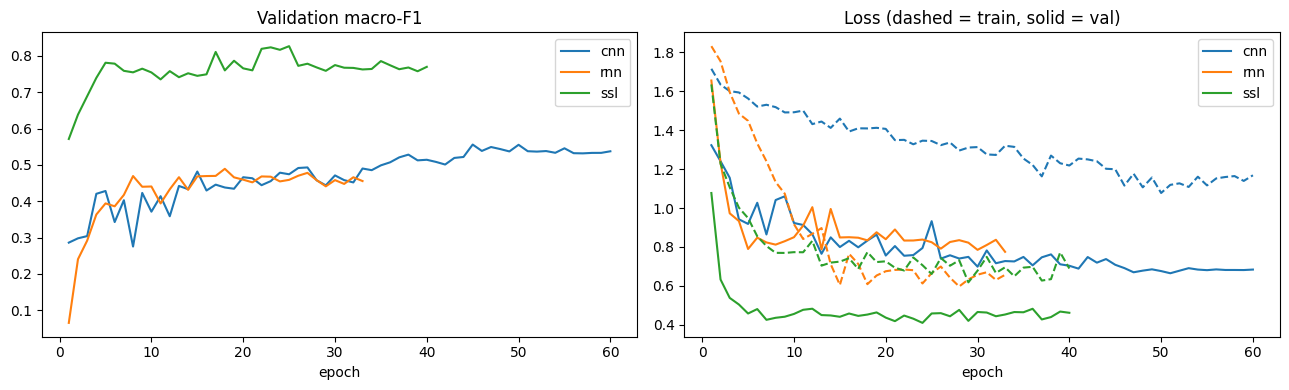

SSL layer weights (top 5 layers): {9: 0.052, 10: 0.05, 12: 0.048, 11: 0.047, 13: 0.046}


In [14]:
# Learning curves
colors = dict(cnn="tab:blue", rnn="tab:orange", ssl="tab:green")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in main["hist"].items():
    ax[0].plot(h.epoch, h.val_f1, label=name, color=colors[name])
    ax[1].plot(h.epoch, h.train_loss, color=colors[name], ls="--")
    ax[1].plot(h.epoch, h.val_loss, color=colors[name], label=name)
ax[0].set_title("Validation macro-F1"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Loss (dashed = train, solid = val)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(WORK / "learning_curves.png", dpi=150); plt.show()
if "ssl" in main["models"]:
    w = torch.softmax(main["models"]["ssl"].layer_logits.detach().cpu(), 0).numpy()
    print("SSL layer weights (top 5 layers):", {int(i): round(float(w[i]), 3) for i in np.argsort(-w)[:5]})

<div dir="rtl" align="right">

## ۹. Ensemble و ارزیابی نهایی

میانگین وزن‌دار احتمال‌های سه مدل؛ وزن‌ها روی **validation** (شبکه‌ی گسسته با گام ۰٫۱ و مجموع ۱) انتخاب می‌شوند، نه روی test. در جدول، ستون‌های `val` برای ensemble تنظیم‌شده کمی خوش‌بینانه‌اند؛ **عدد معتبر ستون `test` است**.

معیارها:
**Acc** نسبت پیش‌بینی درست؛
**UAR** میانگین recall کلاس‌ها (معیار استاندارد SER برای داده‌ی نامتوازن)؛
**MacroF1** میانگین F1 کلاس‌ها؛
**WeightedF1** میانگین F1 با وزن فراوانی کلاس (توسط کلاس‌های پرنمونه تحت‌تأثیر است، مثل معیاری که در نسخه‌ی قبل گزارش می‌شد).

</div>

In [15]:
def ens_probs(res, split, names, w):
    return sum(wi * res["probs"][split][n] for wi, n in zip(w, names))


def tune_ensemble(res, step=0.1):
    names = list(res["probs"]["val"])
    k, best = int(round(1 / step)), None
    for c in itertools.product(range(k + 1), repeat=len(names)):
        if sum(c) != k:
            continue
        w = np.array(c) / k
        m = metrics(res["y"]["val"], ens_probs(res, "val", names, w).argmax(1))
        key = (m["MacroF1"], m["UAR"])
        if best is None or key > best[0]:
            best = (key, w)
    return names, best[1], best[0][0]


def summary_table(res, names, w_best):
    out, eq = {}, np.ones(len(names)) / len(names)
    for split in ("val", "test"):
        y_s = res["y"][split]
        row = {n: metrics(y_s, res["probs"][split][n].argmax(1)) for n in names}
        row["Ensemble (equal weights)"] = metrics(y_s, ens_probs(res, split, names, eq).argmax(1))
        row["Ensemble (val-tuned)"] = metrics(y_s, ens_probs(res, split, names, w_best).argmax(1))
        out[split] = pd.DataFrame(row).T
    return pd.concat(out, axis=1).round(4)


names, w_best, val_score = tune_ensemble(main)
print("ensemble weights:", dict(zip(names, w_best.round(2).tolist())), f"| val macro-F1 = {val_score:.4f}")
display(summary_table(main, names, w_best))

ensemble weights: {'cnn': 0.0, 'rnn': 0.0, 'ssl': 1.0} | val macro-F1 = 0.8269


val                               test          \
                             Acc     UAR MacroF1 WeightedF1     Acc     UAR   
cnn                       0.7994  0.5301  0.5561     0.7863  0.6692  0.5038   
rnn                       0.7599  0.4893  0.4893     0.7511  0.5856  0.4273   
ssl                       0.8936  0.7833  0.8269     0.8905  0.8783  0.8022   
Ensemble (equal weights)  0.8541  0.5964  0.6252     0.8399  0.7909  0.6741   
Ensemble (val-tuned)      0.8936  0.7833  0.8269     0.8905  0.8783  0.8022   

                                             
                         MacroF1 WeightedF1  
cnn                       0.4931     0.6496  
rnn                       0.4267     0.5684  
ssl                       0.8247     0.8765  
Ensemble (equal weights)  0.7076     0.7834  
Ensemble (val-tuned)      0.8247     0.8765

,precision,recall,f1-score,support
Anger,0.957,0.978,0.968,92.000
Sadness,0.881,0.867,0.874,60.000
Fear,1.000,0.500,0.667,8.000
Happiness,0.840,0.875,0.857,24.000
Surprise,0.778,0.750,0.764,28.000
Neutral,0.796,0.843,0.819,51.000
accuracy,0.878,0.878,0.878,0.878
macro avg,0.875,0.802,0.825,263.000
weighted avg,0.880,0.878,0.877,263.000


Test set: 263 utterances. 95% bootstrap CI (small classes make these intervals wide):


,point,ci_low,ci_high
Acc,0.8783,0.8402,0.9163
UAR,0.8022,0.7284,0.8775
MacroF1,0.8247,0.7400,0.8860
WeightedF1,0.8765,0.8353,0.9156


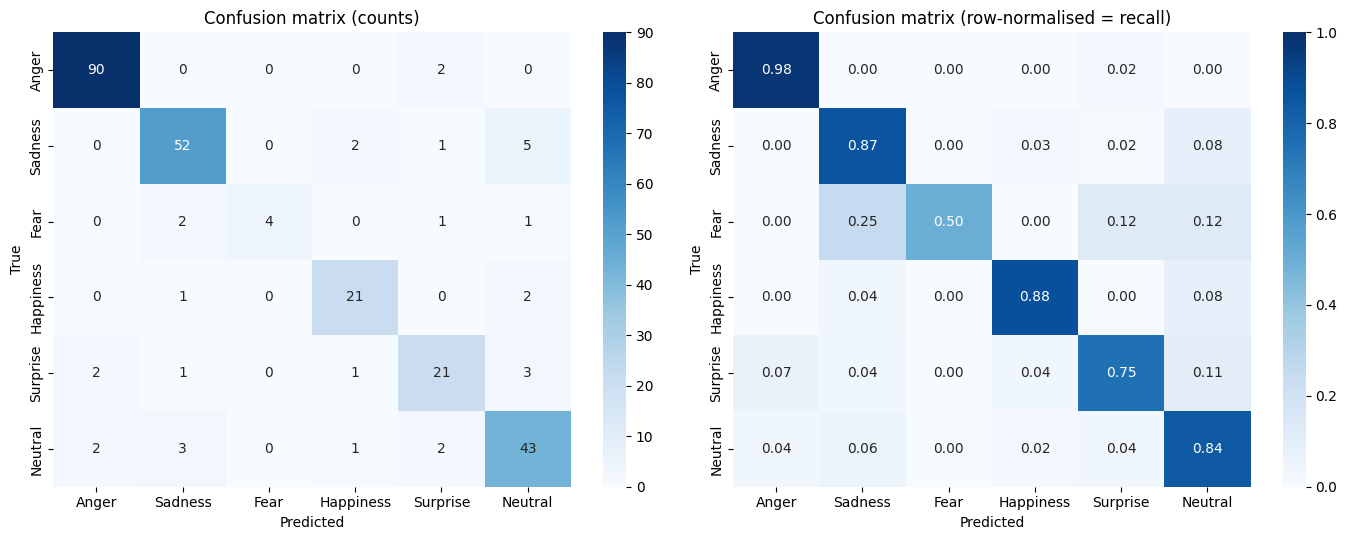

In [16]:
y_te = main["y"]["test"]
p_te = ens_probs(main, "test", names, w_best)
pred_te = p_te.argmax(1)

# ---- per-class report
rep = classification_report(y_te, pred_te, labels=list(range(N_CLASSES)), target_names=CLASS_NAMES,
                            output_dict=True, zero_division=0)
display(pd.DataFrame(rep).T.round(3))

# ---- bootstrap 95% confidence intervals on the test set (resampling utterances)
rng = np.random.default_rng(CFG.seed)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    boot.append(metrics(y_te[i], pred_te[i]))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"point": pd.Series(metrics(y_te, pred_te)),
                   "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)}).round(4)
print(f"Test set: {len(y_te)} utterances. 95% bootstrap CI (small classes make these intervals wide):")
display(ci)

# ---- confusion matrices (counts + row-normalised)
cm = confusion_matrix(y_te, pred_te, labels=list(range(N_CLASSES)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
for a, t in zip(ax, ("Confusion matrix (counts)", "Confusion matrix (row-normalised = recall)")):
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(t)
plt.tight_layout(); plt.savefig(WORK / "confusion_matrix.png", dpi=150); plt.show()

<div dir="rtl" align="right">

## ۱۰. ذخیره‌ی مدل‌ها و استنتاج روی یک فایل

مدل‌ها، آمار نرمال‌سازی، وزن‌های ensemble و تنظیمات در یک فایل ذخیره می‌شوند. تابع `predict_emotion` همان مسیر کامل (پیش‌پردازش ← ویژگی ← هر سه مدل ← ensemble) را روی یک فایل wav اجرا می‌کند.

</div>

saved: /content/ser_outputs/ser_ensemble.pt
true label: Anger


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


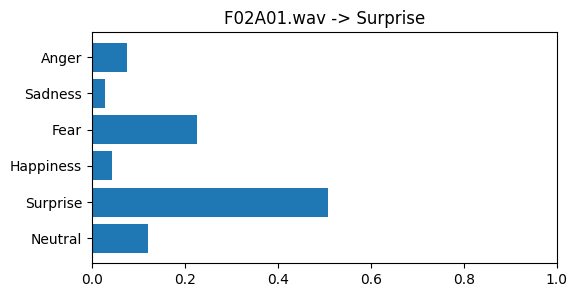

{'Anger': 0.0756, 'Sadness': 0.0286, 'Fear': 0.2261, 'Happiness': 0.0423, 'Surprise': 0.5075, 'Neutral': 0.1198}


In [17]:
artifact = dict(
    cfg=asdict(CFG), class_names=CLASS_NAMES, ensemble_names=names, ensemble_weights=w_best.tolist(),
    states={k: m.state_dict() for k, m in main["models"].items()},
    stats={k: tuple(t.cpu() for t in v) for k, v in main["stats"].items()},
)
torch.save(artifact, WORK / "ser_ensemble.pt")
print("saved:", WORK / "ser_ensemble.pt")
# reload later:  art = torch.load(WORK / "ser_ensemble.pt");  model.load_state_dict(art["states"]["cnn"])

_SSL_MODEL = None

@torch.no_grad()
def predict_emotion(path, res=main, names=names, weights=w_best, plot=True):
    """Run the full pipeline on one wav file and return {emotion: probability}."""
    global _SSL_MODEL
    wav = load_waveform(path)
    lm, mf = wave_to_feats(wav)
    n, probs = CFG.crop_frames, {}
    for key, feat in (("cnn", lm), ("rnn", mf)):
        mean, std = res["stats"][key]
        x = ((crop_or_tile(feat, n, False) - mean) / std)[None].to(device)
        res["models"][key].eval()
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            probs[key] = F.softmax(res["models"][key](x).float(), 1)[0].cpu().numpy()
    if "ssl" in names:
        if _SSL_MODEL is None:
            _SSL_MODEL = load_ssl()
        mean, std = res["stats"]["ssl"]
        e = (torch.from_numpy(ssl_embed(_SSL_MODEL, wav).astype(np.float32)) - mean) / std
        res["models"]["ssl"].eval()
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            probs["ssl"] = F.softmax(res["models"]["ssl"](e[None].to(device)).float(), 1)[0].cpu().numpy()
    p = sum(w * probs[k] for w, k in zip(weights, names))
    out = {k: round(float(v), 4) for k, v in zip(CLASS_NAMES, p)}
    if plot:
        plt.figure(figsize=(6, 3)); plt.barh(CLASS_NAMES, p); plt.xlim(0, 1)
        plt.title(f"{Path(path).name} -> {CLASS_NAMES[int(p.argmax())]}"); plt.gca().invert_yaxis(); plt.show()
    return out


demo = df.iloc[main["idx"][2][0]]
print("true label:", demo.emotion)
print(predict_emotion(demo.path))

<div dir="rtl" align="right">

## ۱۱.  اعتبارسنجی متقاطع مستقل از گوینده

نتیجه‌ی یک تقسیم تکی، به‌خصوص برای کلاس‌هایی مثل Fear که فقط چند نمونه‌ی تست دارند، پرنوسان است. با `RUN_CV = True` همین پایپ‌لاین روی چند fold اجرا می‌شود و میانگین ± انحراف معیار گزارش می‌شود. **هشدار:** زمان اجرا تقریباً `n_cv_folds` برابر بخش ۸ است.

</div>

In [18]:
RUN_CV = False
n_cv_folds = 5

if RUN_CV:
    assert CFG.split_mode == "speaker", "cross-validation here is speaker-independent; set split_mode='speaker'"
    rows = []
    for k in range(n_cv_folds):
        tr_k, va_k, te_k = make_splits(df, CFG, fold=k)
        r = train_all_models(tr_k, va_k, te_k, tag=f"cv{k}")
        nm, w, _ = tune_ensemble(r)
        row = dict(fold=k, **metrics(r["y"]["test"], ens_probs(r, "test", nm, w).argmax(1)))
        for n_ in nm:
            row[f"F1_{n_}"] = f1_score(r["y"]["test"], r["probs"]["test"][n_].argmax(1), average="macro", zero_division=0)
        rows.append(row)
        del r; gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    cv = pd.DataFrame(rows).set_index("fold")
    display(cv.round(4))
    print("mean ± std over folds (ensemble, test):")
    print(pd.DataFrame({"mean": cv.mean(), "std": cv.std()}).round(4))


<div dir="rtl" align="right">

## ۱۳. بازنمایی تفکیک‌شده و مستقل از گوینده با XLS-R

در این بخش، مدل‌های قبلی دست‌نخورده باقی می‌مانند و یک مدل جدید روی همان امبدینگ‌های XLS-R اضافه می‌شود. امبدینگ موجود برای هر لایه شامل میانگین و انحراف معیار زمانی است (`[layers, 2 × hidden]`). این نمایش pooled، توالی زمانی را نگه نمی‌دارد؛ بااین‌حال برای جلوگیری از افزایش چندگیگابایتی حافظه، همین آمار لایه‌ایِ موجود را به‌عنوان ورودی مشترک استفاده می‌کنیم. بنابراین این آزمایش، disentanglement روی آمار utterance-level XLS-R است، نه روی فریم‌های خام.

معماری: وزن‌دهی یادگیری‌پذیر لایه‌ها ← shared MLP ← دو projection مجزا (`Z_emotion`, `Z_speaker`). طبقه‌بند احساس فقط `Z_emotion` را می‌بیند؛ طبقه‌بند هویت فقط `Z_speaker` را. یک طبقه‌بند adversarial نیز `Z_emotion` را از طریق GRL دریافت می‌کند.

**تابع هدف.** با \(R_\lambda\) به‌عنوان Gradient Reversal Layer داریم:
\[
\mathcal L = \mathcal L_{emo} + \alpha\mathcal L_{spk}
+ \beta\mathcal L_{adv} + \gamma\mathcal L_{orth}.
\]
هر سه CE به‌صورت معمولی برای head متناظر کمینه می‌شوند؛ GRL گرادیانِ ورودی به `Z_emotion` را در شاخه‌ی adversarial با ضریب \(-\lambda\) برمی‌گرداند. در نتیجه adversarial head یاد می‌گیرد گوینده را پیش‌بینی کند، اما projection/shared representation یاد می‌گیرد این پیش‌بینی را دشوار کند. جمله‌ی \(\mathcal L_{orth}\) مربع میانگین cosine similarity بین دو بردار نرمال‌شده است و فقط یک قید کمکی است.

**محدودیت مهم برچسب گوینده:** فقط شناسه‌های موجود در train به کلاس‌های speaker-head نگاشت می‌شوند. utteranceهای validation/test هیچ‌گاه در آموزش speaker-head شرکت نمی‌کنند و شناسه‌های دیده‌نشده به کلاس جعلی تبدیل نمی‌شوند. انتخاب checkpoint صرفاً با Macro-F1 احساس روی validation انجام می‌شود.
</div>


In [19]:

# Reproducible settings for the disentanglement experiment.
DSEED = CFG.seed
D_CFG = {
    "z_dim": 256, "hidden_dim": 512, "dropout": 0.30,
    "epochs": 60, "lr": 3e-4, "weight_decay": 1e-3,
    "lambda_speaker": 0.5, "lambda_adversarial": 0.5,
    "lambda_orthogonal": 0.02, "grl_max": 1.0,
    "batch_size": min(CFG.batch_size, 32), "patience": 12,
    "probe_fraction": 0.20,
}
assert EMB is not None, "XLS-R embeddings are required. Set CFG.use_ssl=True and run the SSL extraction cell."
assert CFG.split_mode == "speaker", "The primary disentanglement experiment requires speaker-independent splits."
# Re-check all three partitions; no speaker can cross a boundary.
_spk_sets = {k: set(df.speaker.iloc[v]) for k, v in
             (("train", train_idx), ("val", val_idx), ("test", test_idx))}
assert not (_spk_sets["train"] & _spk_sets["val"])
assert not (_spk_sets["train"] & _spk_sets["test"])
assert not (_spk_sets["val"] & _spk_sets["test"])
assert len(np.unique(df.speaker.iloc[train_idx])) >= 2, "Need >=2 training speakers."

# Speaker IDs are encoded using TRAIN speakers only. Never fit this mapping on val/test.
TRAIN_SPEAKERS = sorted(df.speaker.iloc[train_idx].unique().tolist())
SPK_TO_TRAIN_ID = {s: i for i, s in enumerate(TRAIN_SPEAKERS)}
N_TRAIN_SPK = len(TRAIN_SPEAKERS)
train_spk_ids = np.array([SPK_TO_TRAIN_ID[s] for s in df.speaker.iloc[train_idx]])
assert set(train_spk_ids) == set(range(N_TRAIN_SPK))
assert all(s not in SPK_TO_TRAIN_ID for s in _spk_sets["val"] | _spk_sets["test"])

# Normalization uses training utterances only. Keep the [layer, 2*hidden] structure.
_emb_train = EMB[train_idx].astype(np.float32)
D_EMB_MEAN = torch.from_numpy(_emb_train.mean(axis=0))
D_EMB_STD = torch.from_numpy(_emb_train.std(axis=0) + 1e-5)
del _emb_train

class DisentangledDataset(Dataset):
    def __init__(self, indices, training=False):
        self.indices = np.asarray(indices, dtype=np.int64)
        self.training = training
    def __len__(self): return len(self.indices)
    def __getitem__(self, j):
        ix = int(self.indices[j])
        x = torch.from_numpy(EMB[ix].astype(np.float32))
        x = (x - D_EMB_MEAN) / D_EMB_STD
        # Unknown speakers intentionally carry -1 outside training.
        sid = SPK_TO_TRAIN_ID.get(df.speaker.iloc[ix], -1)
        return x, int(df.label.iloc[ix]), int(sid)

def disentangled_loader(indices, shuffle=False, batch_size=None):
    return DataLoader(DisentangledDataset(indices), batch_size=batch_size or D_CFG["batch_size"],
                      shuffle=shuffle, drop_last=False, num_workers=0,
                      pin_memory=(device.type == "cuda"))

class GradientReversal(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, coefficient):
        ctx.coefficient = float(coefficient)
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.coefficient * grad_output, None

def grad_reverse(x, coefficient=1.0):
    return GradientReversal.apply(x, coefficient)

class XLSRDisentangledSER(nn.Module):
    def __init__(self, n_layers, input_dim, n_emotions, n_speakers, z_dim=256, hidden=512, dropout=0.3):
        super().__init__()
        self.layer_logits = nn.Parameter(torch.zeros(n_layers))
        self.input_norm = nn.LayerNorm(input_dim)
        self.shared = nn.Sequential(nn.Linear(input_dim, hidden), nn.GELU(),
                                    nn.Dropout(dropout), nn.Linear(hidden, hidden), nn.GELU())
        self.emotion_projection = nn.Sequential(nn.Linear(hidden, z_dim), nn.LayerNorm(z_dim), nn.GELU())
        self.speaker_projection = nn.Sequential(nn.Linear(hidden, z_dim), nn.LayerNorm(z_dim), nn.GELU())
        self.emotion_head = nn.Linear(z_dim, n_emotions)
        self.speaker_head = nn.Linear(z_dim, n_speakers)
        self.adversarial_speaker_head = nn.Sequential(nn.Linear(z_dim, hidden // 2), nn.GELU(),
                                                       nn.Dropout(dropout), nn.Linear(hidden // 2, n_speakers))
    def forward(self, x, grl_lambda=1.0):
        # x [B,L,D] -> layer weighted shared feature [B,D]
        w = torch.softmax(self.layer_logits, dim=0)
        shared = self.shared(self.input_norm((x * w[None, :, None]).sum(dim=1)))
        z_emotion = self.emotion_projection(shared)
        z_speaker = self.speaker_projection(shared)
        return {
            "emotion_logits": self.emotion_head(z_emotion),
            "speaker_logits": self.speaker_head(z_speaker),
            "adversarial_logits": self.adversarial_speaker_head(grad_reverse(z_emotion, grl_lambda)),
            "z_emotion": z_emotion, "z_speaker": z_speaker,
        }

def orthogonality_loss(z_e, z_s):
    ze = F.normalize(z_e.float(), dim=1)
    zs = F.normalize(z_s.float(), dim=1)
    return (ze * zs).sum(dim=1).pow(2).mean()

# GRL unit test: forward is identity; backward reverses and scales gradient.
_test_x = torch.tensor([[1.0, -2.0]], requires_grad=True)
_test_y = grad_reverse(_test_x, 0.7)
assert torch.equal(_test_x.detach(), _test_y.detach())
_test_y.sum().backward()
assert torch.allclose(_test_x.grad, torch.full_like(_test_x, -0.7))
del _test_x, _test_y
_model_check = XLSRDisentangledSER(*EMB.shape[1:], N_CLASSES, N_TRAIN_SPK,
                                    z_dim=D_CFG["z_dim"], hidden=D_CFG["hidden_dim"],
                                    dropout=D_CFG["dropout"])
with torch.no_grad():
    _o = _model_check(torch.randn(3, *EMB.shape[1:]))
assert _o["emotion_logits"].shape == (3, N_CLASSES)
assert _o["speaker_logits"].shape == (3, N_TRAIN_SPK)
assert _o["adversarial_logits"].shape == (3, N_TRAIN_SPK)
assert _o["z_emotion"].shape == _o["z_speaker"].shape == (3, D_CFG["z_dim"])
print("Disentangled shape checks passed:", {k: tuple(v.shape) for k, v in _o.items()})
del _model_check, _o


Disentangled shape checks passed: {'emotion_logits': (3, 6), 'speaker_logits': (3, 71), 'adversarial_logits': (3, 71), 'z_emotion': (3, 256), 'z_speaker': (3, 256)}



<div dir="rtl" align="right">

## ۱۴. آموزش، ablation و انتخاب checkpoint

دو نسخه با مقدارهای یکسان و seed یکسان آموزش می‌بینند: (الف) مدل کامل با adversarial speaker loss و (ب) ablation با \(\beta=0\). هر دو همچنان speaker-head کمکی روی `Z_speaker` دارند. برای جلوگیری از آلودگی split، speaker loss فقط برای نمونه‌های train با speaker ID آموزش معتبر محاسبه می‌شود. اعتبارسنجی و early stopping فقط با برچسب احساس انجام می‌شود.

</div>


In [20]:

def _d_metrics(y, p):
    return metrics(np.asarray(y), np.asarray(p).argmax(1))

def _grl_schedule(step, total):
    # Smooth DANN ramp-up, bounded by grl_max.
    q = step / max(total, 1)
    return D_CFG["grl_max"] * (2.0 / (1.0 + math.exp(-10.0 * q)) - 1.0)

@torch.no_grad()
def _d_eval(model, loader):
    model.eval()
    ys, probs, losses = [], [], []
    for x, y, _sid in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            out = model(x, grl_lambda=0.0)
        logits = out["emotion_logits"].float()
        losses.append(F.cross_entropy(logits, y.to(device), reduction="mean").item())
        probs.append(F.softmax(logits, 1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(probs), np.concatenate(ys), float(np.mean(losses))

def train_disentangled(adversarial=True, run_name="disentangled"):
    seed_everything(DSEED)
    model = XLSRDisentangledSER(*EMB.shape[1:], N_CLASSES, N_TRAIN_SPK,
                                z_dim=D_CFG["z_dim"], hidden=D_CFG["hidden_dim"],
                                dropout=D_CFG["dropout"]).to(device)
    tr_loader = disentangled_loader(train_idx, shuffle=True)
    va_loader = disentangled_loader(val_idx, shuffle=False)
    opt = torch.optim.AdamW(model.parameters(), lr=D_CFG["lr"], weight_decay=D_CFG["weight_decay"])
    epochs = D_CFG["epochs"]
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=D_CFG["lr"],
             total_steps=epochs * max(len(tr_loader), 1), pct_start=0.15)
    scaler = torch.amp.GradScaler(device.type, enabled=AMP)
    ytr = df.label.values[train_idx]
    cw_emo = class_weights(ytr).to(device)
    cw_spk = torch.ones(N_TRAIN_SPK, device=device)
    # Balanced speaker weights are not used: each speaker's natural utterance count is retained.
    ce_emo = nn.CrossEntropyLoss(weight=cw_emo, label_smoothing=CFG.label_smoothing)
    ce_spk = nn.CrossEntropyLoss(weight=cw_spk)
    best_f1, best_epoch, patience_count = -1.0, 0, 0
    history, step = [], 0
    ckpt_path = WORK / f"{run_name}.pt"
    total_steps = epochs * max(len(tr_loader), 1)
    for epoch in range(1, epochs + 1):
        model.train()
        totals = dict(total=0., emo=0., spk=0., adv=0., orth=0.)
        batches = 0
        for x, y, sid in tr_loader:
            x, y, sid = x.to(device, non_blocking=True), y.to(device), sid.to(device)
            lam = _grl_schedule(step, total_steps) if adversarial else 0.0
            opt.zero_grad(set_to_none=True)
            try:
                with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                    out = model(x, grl_lambda=lam)
                    le = ce_emo(out["emotion_logits"].float(), y)
                    valid = sid >= 0
                    if valid.any():
                        ls = ce_spk(out["speaker_logits"].float()[valid], sid[valid])
                        la = ce_spk(out["adversarial_logits"].float()[valid], sid[valid])
                    else:
                        ls = le.new_zeros(())
                        la = le.new_zeros(())
                    lo = orthogonality_loss(out["z_emotion"], out["z_speaker"])
                    beta = D_CFG["lambda_adversarial"] if adversarial else 0.0
                    loss = (le + D_CFG["lambda_speaker"] * ls + beta * la
                            + D_CFG["lambda_orthogonal"] * lo)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
            except torch.cuda.OutOfMemoryError:
                if device.type == "cuda":
                    opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                raise RuntimeError("CUDA OOM in disentangled training. Reduce D_CFG['batch_size'] (e.g. 16 or 8), then rerun this cell.")
            for k, v in zip(("total", "emo", "spk", "adv", "orth"), (loss, le, ls, la, lo)):
                totals[k] += float(v.detach())
            batches += 1; step += 1
        probs, yv, vloss = _d_eval(model, va_loader)
        vm = _d_metrics(yv, probs)
        row = {"epoch": epoch, **{f"train_{k}": v / max(batches, 1) for k, v in totals.items()},
               "val_loss": vloss, "val_macro_f1": vm["MacroF1"], "val_uar": vm["UAR"]}
        history.append(row)
        if vm["MacroF1"] > best_f1:
            best_f1, best_epoch, patience_count = vm["MacroF1"], epoch, 0
            torch.save({"state_dict": model.state_dict(), "epoch": epoch, "val_macro_f1": best_f1,
                        "config": dict(D_CFG, adversarial=adversarial),
                        "train_speakers": TRAIN_SPEAKERS}, ckpt_path)
        else:
            patience_count += 1
        print(f"{run_name} ep {epoch:02d} | loss {row['train_total']:.3f} | "
              f"val macro-F1 {vm['MacroF1']:.3f} | best {best_f1:.3f}@{best_epoch}")
        if patience_count >= D_CFG["patience"]:
            break
    saved = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(saved["state_dict"])
    return model, pd.DataFrame(history), saved

if EMB is None:
    raise RuntimeError("XLS-R embeddings are missing; cannot run this experiment.")
disentangled_model, disentangled_history, disentangled_ckpt = train_disentangled(
    adversarial=True, run_name="xlsr_disentangled_grl")
noadv_model, noadv_history, noadv_ckpt = train_disentangled(
    adversarial=False, run_name="xlsr_disentangled_no_adversary")


xlsr_disentangled_grl ep 01 | loss 5.881 | val macro-F1 0.536 | best 0.536@1
xlsr_disentangled_grl ep 02 | loss 5.152 | val macro-F1 0.623 | best 0.623@2
xlsr_disentangled_grl ep 03 | loss 4.516 | val macro-F1 0.749 | best 0.749@3
xlsr_disentangled_grl ep 04 | loss 3.880 | val macro-F1 0.764 | best 0.764@4
xlsr_disentangled_grl ep 05 | loss 3.284 | val macro-F1 0.751 | best 0.764@4
xlsr_disentangled_grl ep 06 | loss 2.876 | val macro-F1 0.750 | best 0.764@4
xlsr_disentangled_grl ep 07 | loss 2.679 | val macro-F1 0.831 | best 0.831@7
xlsr_disentangled_grl ep 08 | loss 2.535 | val macro-F1 0.735 | best 0.831@7
xlsr_disentangled_grl ep 09 | loss 2.433 | val macro-F1 0.755 | best 0.831@7
xlsr_disentangled_grl ep 10 | loss 2.380 | val macro-F1 0.765 | best 0.831@7
xlsr_disentangled_grl ep 11 | loss 2.357 | val macro-F1 0.775 | best 0.831@7
xlsr_disentangled_grl ep 12 | loss 2.321 | val macro-F1 0.741 | best 0.831@7
xlsr_disentangled_grl ep 13 | loss 2.326 | val macro-F1 0.739 | best 0.831@7

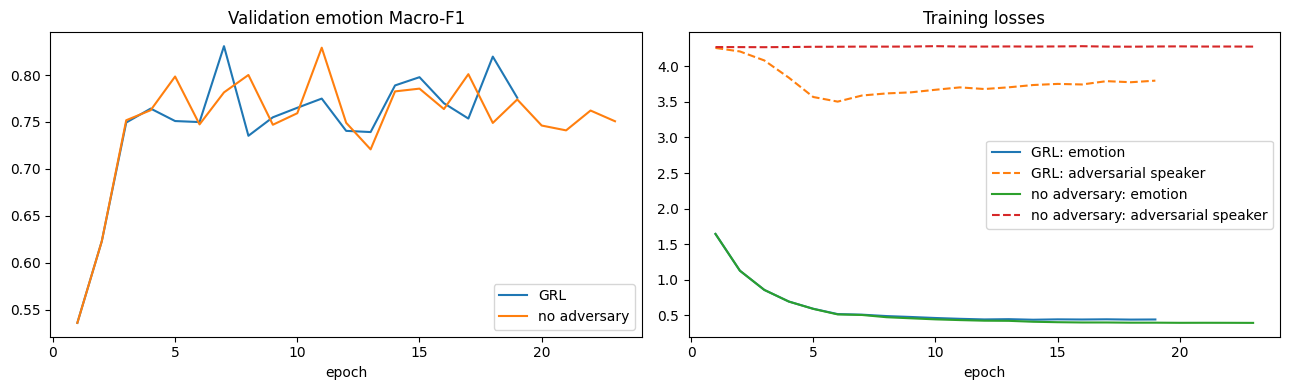

,Acc,UAR,MacroF1,WeightedF1
XLS-R baseline,0.8783,0.8022,0.8247,0.8765
XLS-R + disentangled + GRL,0.8555,0.8282,0.8208,0.8588
XLS-R + disentangled (no GRL),0.8555,0.7777,0.7895,0.8531
Existing ensemble,0.8783,0.8022,0.8247,0.8765


Test speaker IDs are disjoint from training speaker IDs: True
Train/val/test speaker counts: {'train': 71, 'val': 8, 'test': 8}


In [21]:

# Learning curves: both variants. Validation is emotion-only and never drives speaker-head fitting.
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, hist in (("GRL", disentangled_history), ("no adversary", noadv_history)):
    ax[0].plot(hist.epoch, hist.val_macro_f1, label=label)
    ax[1].plot(hist.epoch, hist.train_emo, label=f"{label}: emotion")
    ax[1].plot(hist.epoch, hist.train_adv, ls="--", label=f"{label}: adversarial speaker")
ax[0].set_title("Validation emotion Macro-F1"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Training losses"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(WORK / "disentanglement_training_curves.png", dpi=150); plt.show()

d_test_loader = disentangled_loader(test_idx, shuffle=False)
d_val_loader = disentangled_loader(val_idx, shuffle=False)
p_d_val, y_d_val, _ = _d_eval(disentangled_model, d_val_loader)
p_d_test, y_d_test, _ = _d_eval(disentangled_model, d_test_loader)
p_na_val, _, _ = _d_eval(noadv_model, d_val_loader)
p_na_test, _, _ = _d_eval(noadv_model, d_test_loader)
assert np.array_equal(y_d_test, df.label.values[test_idx])

# Existing XLS-R baseline and existing ensemble predictions are retained from `main`.
comparison_rows = {
    "XLS-R baseline": metrics(main["y"]["test"], main["probs"]["test"]["ssl"].argmax(1)),
    "XLS-R + disentangled + GRL": metrics(y_d_test, p_d_test.argmax(1)),
    "XLS-R + disentangled (no GRL)": metrics(y_d_test, p_na_test.argmax(1)),
}
if "names" in globals() and "w_best" in globals():
    comparison_rows["Existing ensemble"] = metrics(main["y"]["test"],
        ens_probs(main, "test", names, w_best).argmax(1))
comparison_table = pd.DataFrame(comparison_rows).T
display(comparison_table.round(4))
print("Test speaker IDs are disjoint from training speaker IDs:",
      len(_spk_sets["train"] & _spk_sets["test"]) == 0)
print("Train/val/test speaker counts:",
      {k: len(v) for k, v in _spk_sets.items()})



<div dir="rtl" align="right">

## ۱۵. سنجش نشت هویت در `Z_emotion` با probe

دقت closed-set شناسایی گوینده روی testِ دارای هویت‌های کاملاً جدید، معیار معناداری نیست؛ کلاس‌های test اصلاً در classifier آموزش‌دیده وجود ندارند. در عوض، این probe صرفاً به‌عنوان **تشخیص اطلاعات باقی‌مانده درباره‌ی هویت‌های train** طراحی شده است: از utteranceهای train هر گوینده، بخشی برای آموزش و بخشی برای ارزیابی جدا می‌شود (با حفظ حضور هر گوینده در هر دو قسمت). probe خطی فقط روی `Z_emotion` ثابت آموزش می‌بیند. این probe به test یا validation دسترسی ندارد. دقت/ UAR آن یک تشخیص درون‌هویتی است و نباید به‌عنوان شناسایی هویت‌های unseen تفسیر شود.

</div>


In [22]:

@torch.no_grad()
def collect_z_emotion(model, indices, batch_size=64):
    model.eval()
    loader = disentangled_loader(indices, shuffle=False, batch_size=batch_size)
    zs, ys, ss = [], [], []
    for x, y, sid in loader:
        out = model(x.to(device), grl_lambda=0.0)
        zs.append(out["z_emotion"].float().cpu().numpy())
        ys.append(y.numpy()); ss.append(sid.numpy())
    return np.concatenate(zs), np.concatenate(ys), np.concatenate(ss)

# Hold out utterances within each training identity, never holding out identities.
rng_probe = np.random.default_rng(DSEED)
probe_fit_idx, probe_eval_idx = [], []
for spk in TRAIN_SPEAKERS:
    group = np.asarray([i for i in train_idx if df.speaker.iloc[i] == spk])
    rng_probe.shuffle(group)
    n_eval = max(1, int(round(len(group) * D_CFG["probe_fraction"])))
    if len(group) - n_eval < 1:
        n_eval = max(1, len(group) - 1)
    probe_eval_idx.extend(group[:n_eval].tolist())
    probe_fit_idx.extend(group[n_eval:].tolist())
probe_fit_idx, probe_eval_idx = np.array(probe_fit_idx), np.array(probe_eval_idx)
assert set(df.speaker.iloc[probe_fit_idx]) == set(TRAIN_SPEAKERS)
assert set(df.speaker.iloc[probe_eval_idx]) == set(TRAIN_SPEAKERS)
assert not (set(probe_fit_idx) & set(probe_eval_idx))

def speaker_probe_report(model, label):
    z_fit, _, s_fit = collect_z_emotion(model, probe_fit_idx)
    z_eval, _, s_eval = collect_z_emotion(model, probe_eval_idx)
    # Standardize using probe-fit utterances only.
    mu, sd = z_fit.mean(0), z_fit.std(0) + 1e-5
    z_fit, z_eval = (z_fit - mu) / sd, (z_eval - mu) / sd
    probe = nn.Linear(z_fit.shape[1], N_TRAIN_SPK).to(device)
    opt = torch.optim.AdamW(probe.parameters(), lr=1e-2, weight_decay=1e-3)
    xt = torch.tensor(z_fit, dtype=torch.float32, device=device)
    yt = torch.tensor(s_fit, dtype=torch.long, device=device)
    for _ in range(150):
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(probe(xt), yt)
        loss.backward(); opt.step()
    with torch.no_grad():
        pred = probe(torch.tensor(z_eval, dtype=torch.float32, device=device)).argmax(1).cpu().numpy()
    return {"representation": label, **metrics(s_eval, pred),
            "chance_uniform": 1.0 / N_TRAIN_SPK, "n_probe_eval": len(s_eval)}

probe_rows = [speaker_probe_report(disentangled_model, "GRL Z_emotion"),
              speaker_probe_report(noadv_model, "no-GRL Z_emotion")]
display(pd.DataFrame(probe_rows).set_index("representation").round(4))
print("Interpretation: lower probe UAR/accuracy suggests less recoverable train-speaker identity; "
      "this is not an unseen-speaker identification score.")


,Acc,UAR,MacroF1,WeightedF1,chance_uniform,n_probe_eval
representation,,,,,,
GRL Z_emotion,0.9481,0.8011,0.7940,0.9390,0.0141,482
no-GRL Z_emotion,0.9647,0.8536,0.8523,0.9562,0.0141,482


Interpretation: lower probe UAR/accuracy suggests less recoverable train-speaker identity; this is not an unseen-speaker identification score.


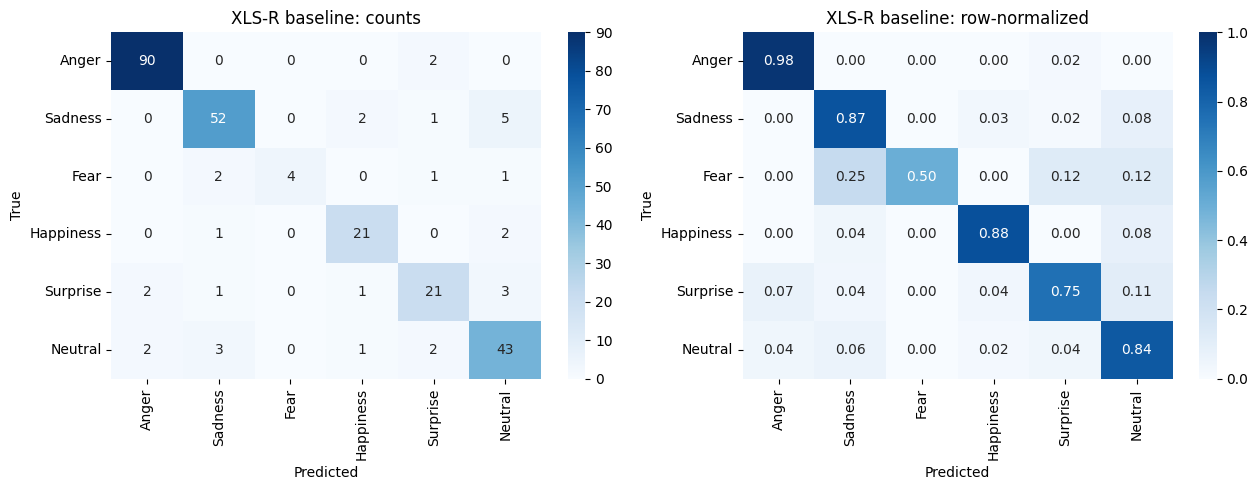

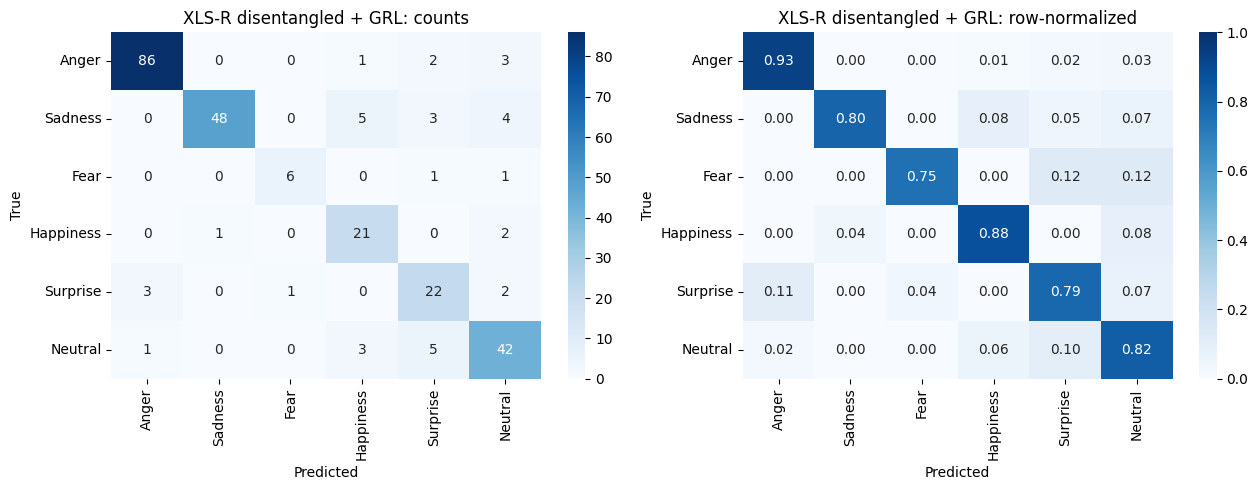

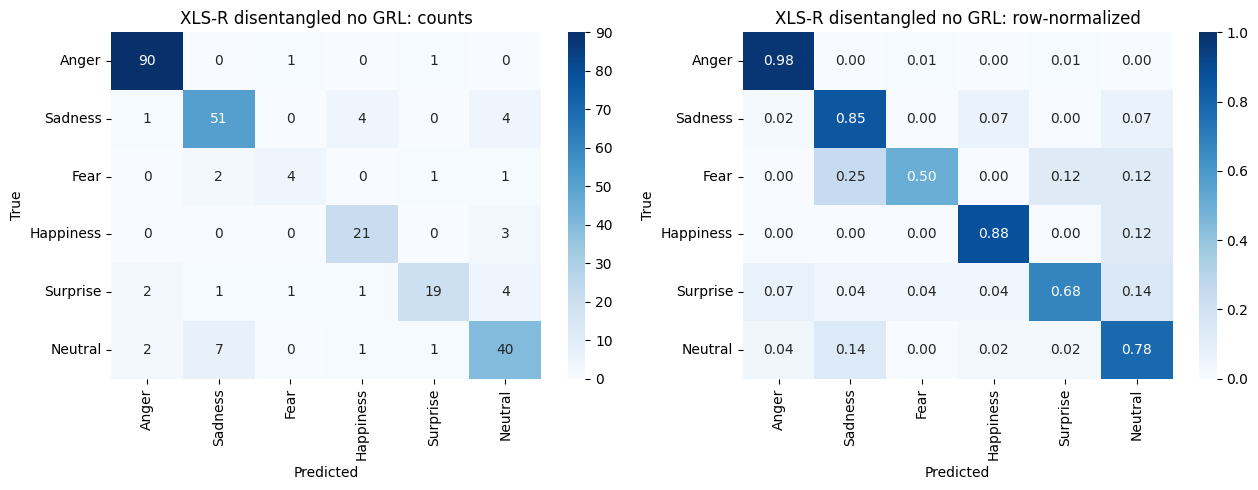

,precision,recall,f1-score,support
Anger,0.956,0.935,0.945,92.000
Sadness,0.980,0.800,0.881,60.000
Fear,0.857,0.750,0.800,8.000
Happiness,0.700,0.875,0.778,24.000
Surprise,0.667,0.786,0.721,28.000
Neutral,0.778,0.824,0.800,51.000
accuracy,0.856,0.856,0.856,0.856
macro avg,0.823,0.828,0.821,263.000
weighted avg,0.869,0.856,0.859,263.000


In [23]:

# Confusion matrices for the baseline and proposed model on the exact same unseen test utterances.
def plot_test_cm(y_true, probabilities, title, filename):
    pred = probabilities.argmax(1)
    cm = confusion_matrix(y_true, pred, labels=np.arange(N_CLASSES))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=ax[0])
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
    ax[0].set_title(f"{title}: counts"); ax[1].set_title(f"{title}: row-normalized")
    for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
    plt.tight_layout(); plt.savefig(WORK / filename, dpi=150); plt.show()

plot_test_cm(main["y"]["test"], main["probs"]["test"]["ssl"], "XLS-R baseline", "cm_xlsr_baseline.png")
plot_test_cm(y_d_test, p_d_test, "XLS-R disentangled + GRL", "cm_xlsr_disentangled.png")
plot_test_cm(y_d_test, p_na_test, "XLS-R disentangled no GRL", "cm_xlsr_disentangled_no_grl.png")

# Per-class reports make minority-class behavior visible.
display(pd.DataFrame(classification_report(y_d_test, p_d_test.argmax(1),
    labels=np.arange(N_CLASSES), target_names=CLASS_NAMES, output_dict=True,
    zero_division=0)).T.round(3))



<div dir="rtl" align="right">

## ۱۶. ذخیره‌ی artifact و استنتاج

Checkpoint شامل وزن‌ها، تنظیمات و فهرست هویت‌های train است. تابع inference تنها امبدینگ XLS-R و مدل احساس را لازم دارد؛ هیچ speaker label یا speaker classifier در تصمیم احساس دخیل نیست. فایل صوتی از همان مسیر preprocessing استفاده می‌کند. تابع زیر خروجی احساس مدل disentangled را برمی‌گرداند.

</div>


In [24]:

disentangled_artifact = {
    "state_dict": {k: v.detach().cpu() for k, v in disentangled_model.state_dict().items()},
    "config": D_CFG, "class_names": CLASS_NAMES,
    "train_speakers": TRAIN_SPEAKERS, "speaker_to_train_id": SPK_TO_TRAIN_ID,
    "embedding_mean": D_EMB_MEAN, "embedding_std": D_EMB_STD,
    "ssl_name": CFG.ssl_name, "ssl_max_sec": CFG.ssl_max_sec,
    "split_speakers": {k: sorted(v) for k, v in _spk_sets.items()},
}
torch.save(disentangled_artifact, WORK / "xlsr_disentangled_ser.pt")
torch.save({"state_dict": {k: v.detach().cpu() for k, v in noadv_model.state_dict().items()},
            "config": dict(D_CFG, adversarial=False)}, WORK / "xlsr_disentangled_no_grl.pt")
with open(WORK / "disentanglement_config.json", "w", encoding="utf-8") as f:
    json.dump({"config": D_CFG, "seed": DSEED, "train_speakers": TRAIN_SPEAKERS,
               "split_speakers": {k: sorted(v) for k, v in _spk_sets.items()},
               "embedding_shape": list(EMB.shape)}, f, ensure_ascii=False, indent=2)
print("Saved checkpoints/config under:", WORK)

@torch.no_grad()
def predict_disentangled_emotion(wav_path, model=disentangled_model, plot=True):
    """Emotion-only inference; speaker labels/heads are not used."""
    ssl_model = load_ssl()
    wav = load_waveform(wav_path)
    emb = torch.from_numpy(ssl_embed(ssl_model, wav).astype(np.float32))
    del ssl_model
    if device.type == "cuda": torch.cuda.empty_cache()
    x = ((emb - D_EMB_MEAN) / D_EMB_STD)[None].to(device)
    model.eval()
    with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
        logits = model(x, grl_lambda=0.0)["emotion_logits"].float()
    p = F.softmax(logits, dim=1)[0].cpu().numpy()
    result = {name: round(float(prob), 4) for name, prob in zip(CLASS_NAMES, p)}
    if plot:
        plt.figure(figsize=(6, 3)); plt.barh(CLASS_NAMES, p); plt.xlim(0, 1)
        plt.title(f"{Path(wav_path).name} -> {CLASS_NAMES[int(p.argmax())]}")
        plt.gca().invert_yaxis(); plt.show()
    return result

# Record the experiment status explicitly: no results are asserted until cells execute.
print("Experiment definitions and checkpoints are in place. Reported metrics above are produced only by execution.")


Saved checkpoints/config under: /content/ser_outputs
Experiment definitions and checkpoints are in place. Reported metrics above are produced only by execution.
